<a href="https://colab.research.google.com/github/CamilaHenaoIbero/Actividad3-M-todosdeaprendizaje-supervisado/blob/main/Actividad_3_aprendizaje_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# Maria Camila Henao Toro
# ==========================================
# ==========================================
# 1. IMPORTAR LIBRERÍAS
# ==========================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


Precisión del modelo: 100.00%

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        32

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



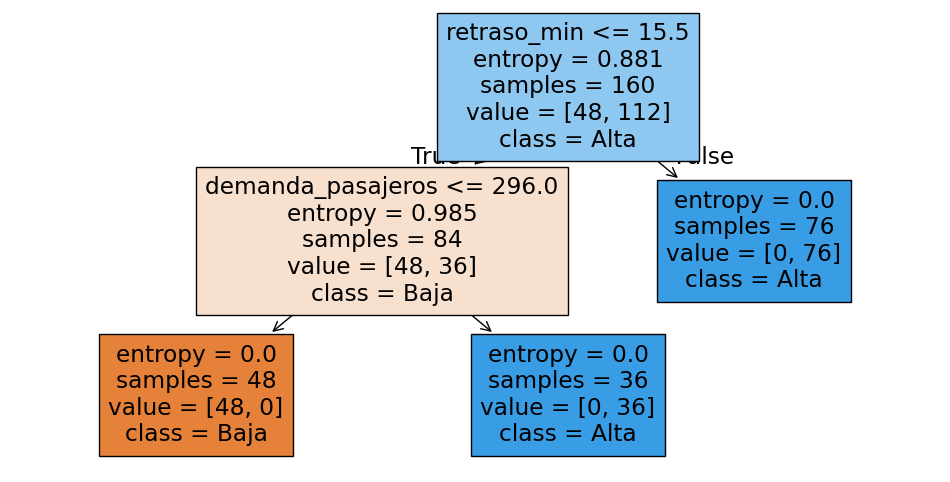

In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# 2. CREAR DATASET (SIMULADO) Y ENTRENAR EL ÁRBOL
# ==========================================
# Simulación de datos del sistema de transporte
np.random.seed(42)

data = pd.DataFrame({
    'hora_dia': np.random.randint(0, 24, 200),       # hora del día
    'dia_semana': np.random.randint(1, 8, 200),      # 1=Lunes, 7=domingo
    'clima': np.random.choice([0, 1], 200),          # 0=soleado, 1=lluvia
    'demanda_pasajeros': np.random.randint(50, 500, 200),
    'retraso_min': np.random.randint(0, 30, 200)
})

# Variable objetivo: alta congestión (1) o baja (0)
data['congestion'] = np.where(
    (data['demanda_pasajeros'] > 300) | (data['retraso_min'] > 15), 1, 0
)

# Separar variables predictoras (X) y objetivo (y)
X = data.drop('congestion', axis=1)
y = data['congestion']

# Dividir datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el Árbol de Decisión
modelo = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

# Predicciones y resultados
y_pred = modelo.predict(X_test)
print(f"Precisión del modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

# Graficar el Árbol de Decisión
plt.figure(figsize=(12, 6))
plot_tree(modelo, feature_names=X.columns, class_names=['Baja', 'Alta'], filled=True)
plt.show()